# 0-instruments: power-resistors

Measure the resistance of each power resistor load and how much it rises with the power it dissipates, so stage 1 can use the loads as known resistances.

## Purpose

Stage 1 characterises the board by driving known loads instead of a motor. The loads are three wirewound power resistors. One is a bare 5 ohm part, one is a 5 ohm part with a capacitor across it, and one is three parts in series. Their nominal values are not good enough for this. A 5 % part at 5 ohm can be off by 0.25 ohm, and a wirewound part warms under load and drifts. This experiment gives each load a measured cold value and a slope against power, so stage 1 can correct a load for the power it ran at.

## Procedure

Four runs of `capture.py`, one per argument. Each run asks for its wiring and waits for Enter. The script refuses to drive the DPS if the DMM's dial is on another function than the one the step needs.

`capture.py leads` comes first and has no load. The DMM is on DC A with the red probe in the A jack (20 A on the B41T+), red to DPS+, black to DPS-, so the DPS current flows through the meter and nothing else. The DPS sits in current limit and steps the current from 0.25 to 2 A, 20 s each. Its voltage readback is the drop across the leads and the DMM's ammeter at each current. That series resistance is inside every driven reading below. It is subtracted at the matching current, because the leads warm with current the same way the loads do.

Each resistor has a wire soldered to each lug, and the clips go on those wires, not on the lugs. The board connects to the same wires in stage 1, so the value measured here is the load as the board sees it, wires included.

`capture.py bare`, `cap` and `series` run one load each, in two wirings.

1. DMM on ohms, probes shorted together, logged for 20 s. This is the probe and lead resistance of the ohms reading.
2. DMM on ohms, probes across the load, DPS leads off the load, logged for 30 s. This is the two-wire rest reading.
3. DMM back on DC A with the red probe in the A jack (20 A on the B41T+). DPS+ to the red probe, black probe to one end of the load, the other end of the load to DPS-. The DPS then steps up in voltage, 25 s per step, 1 to 8 V for the single parts and 3 to 18 V for the series load, with the current limit at 2 A.

## Data

One folder per load, `bare`, `cap`, `series` and `leads`, under the capture folder. The files of the `bare` folder are shown here one by one. The other folders have the same layout. `leads` has no `rest.csv`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from oscnb import b41t, results, show

CAPTURE = Path("../../../telemetry/instruments/power-resistors/capture-1").resolve()
SHOW = CAPTURE / "bare"
SHOW

PosixPath('/home/aaron/projects/OpenServoCore/notebooks/telemetry/instruments/power-resistors/capture-1/bare')

### rest.csv

The DMM log on ohms: `t_host`, `function` (`ohm`), `value` in ohms, `raw`. The probes are shorted first, then across the load.

,t_host,function,value,raw,t
0,00:07:37.589,ohm,0.060,22f104000600,0.000
1,00:07:37.786,ohm,0.060,22f104000600,0.196
2,00:07:38.369,ohm,0.060,22f104000600,0.780
3,00:07:39.151,ohm,0.050,22f104000500,1.561
4,00:07:39.345,ohm,0.050,22f104000500,1.756


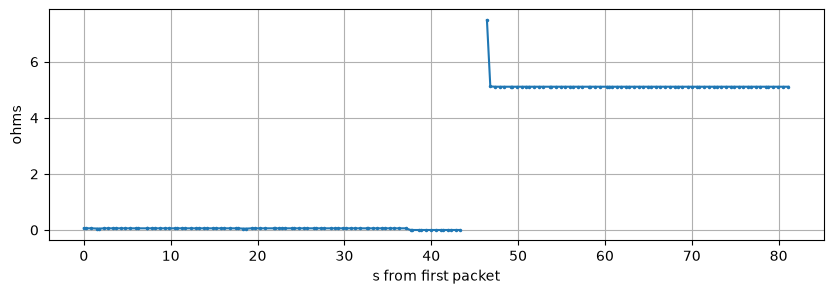

In [2]:
rest = b41t.load(SHOW / "rest.csv")
show(rest)
closed = rest.where(rest.value < 1e3)
closed.plot(x="t", y="value", style=".-", ms=3, figsize=(10, 3), grid=True, legend=False, ylabel="ohms", xlabel="s from first packet");

Two flat stretches, near zero with the probes shorted and then the load. Between them the probes are in the hands and the meter reads open, which it reports as a hundred megohms or more. Those readings are left out of the plot so the axis stays on the load.

### marks.csv

The host time of each wiring change: `t_host`, `mark`. The marks are `shorted` and `load` for the ohms log, and `steps` for the moment the DPS steps began.

In [3]:
marks = pd.read_csv(SHOW / "marks.csv")
show(marks, n=None)

,t_host,mark
0,00:07:37.589,shorted
1,00:08:26.698,load
2,00:10:20.171,steps


### dmm.csv

The DMM log on DC A during the steps: `t_host`, `function` (`DC A`), `value` in amps, `raw`.

,t_host,function,value,raw,t
0,00:10:20.171,DC A,0.000,a3f000000000,0.000
1,00:10:20.559,DC A,0.000,a3f000000000,0.389
2,00:10:20.950,DC A,0.000,a3f000000000,0.780
3,00:10:21.535,DC A,0.000,a3f000000000,1.364
4,00:10:21.924,DC A,0.187,a3f00000bb00,1.754


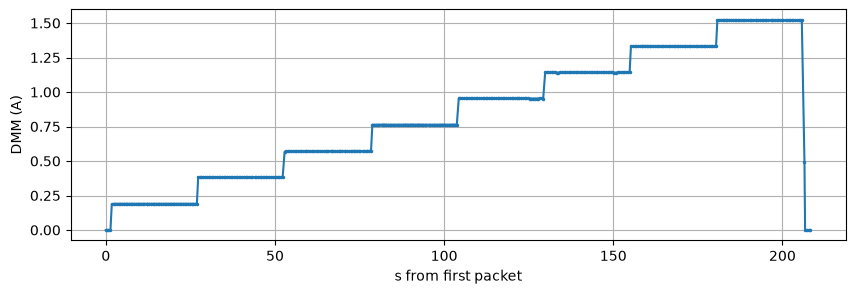

In [4]:
dmm = b41t.load(SHOW / "dmm.csv")
show(dmm)
dmm.plot(x="t", y="value", style=".-", ms=3, figsize=(10, 3), grid=True, legend=False, ylabel="DMM (A)", xlabel="s from first packet");

The current through the load at each DPS level, a staircase.

### dps.csv and events.csv

`dps.csv` is the DPS readback during the steps: `t_host`, `volts`, `amps`. The `amps` column is not used, see the equipment notes. `events.csv` is one row per set command: `t_host`, `volts`. In the `leads` folder that column is `amps`, since that run steps the current limit instead.

,t_host,volts,amps
0,00:10:22.125,0.827,0.135
1,00:10:22.776,1.000,0.190
2,00:10:23.427,1.000,0.191
3,00:10:24.079,1.000,0.191
4,00:10:24.680,1.000,0.190


,t_host,volts
0,00:10:21.424,1
1,00:10:46.977,2
2,00:11:12.532,3
3,00:11:38.184,4
4,00:12:03.739,5
5,00:12:29.292,6
6,00:12:54.897,7
7,00:13:20.500,8


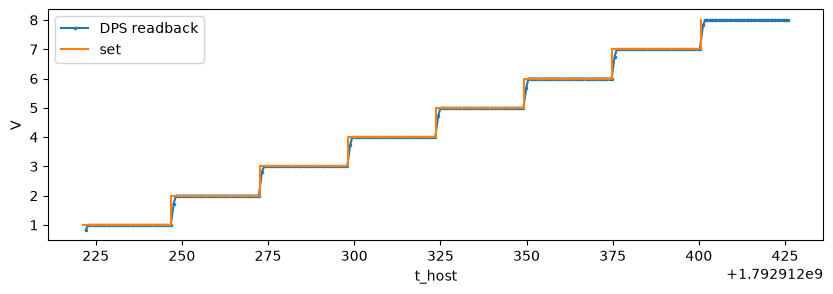

In [5]:
dps = pd.read_csv(SHOW / "dps.csv")
events = pd.read_csv(SHOW / "events.csv")
show(dps); show(events, n=None)
ax = dps.plot(x="t_host", y="volts", style=".-", ms=3, figsize=(10, 3), grid=True, ylabel="V", xlabel="host time (s)", label="DPS readback")
events.plot(x="t_host", y="volts", drawstyle="steps-post", ax=ax, label="set");

The voltage staircase as the DPS saw it, against the levels commanded. The two should agree at every step once the readback settles.

## Method

Each DPS step gives one point. The current is the median of the DMM's DC A readings over the last 40 % of the hold, by which time the readings have settled. The voltage is the median of the DPS readback over the same window. The resistance at that point is

$$R = \frac{V}{I} - R_{leads}$$

where $R_{leads}$ is the leads run's value at the same current, interpolated between its steps. The power it dissipates is $P = R I^2$. Over the power range used, resistance against power is taken as a straight line, $R(P) = R_0 + k P$. The intercept $R_0$ is the cold value and the slope $k$ is the self-heating drift. The line is fitted to the steps at 2 W and above. Below that the current is under 0.4 A, and a fixed error of a few milliamps in the DMM's current reading becomes a percent of the reading. An error of that size is within what a handheld meter's high current range allows. The lowest points carry that error rather than the part, and the plot below checks this. The uncertainty on $R_0$ is the standard error of the fit.

The two-wire rest reading is the median of the ohms log across the load, minus the median with the probes shorted. The DMM pushes about a milliamp through the part for this reading, so it is a different measurement from the driven one. It is reported beside the driven value, not merged into it.

### The leads

The drop across the leads and the ammeter at each current, from the `leads` run. The leads carry the same current as the load in every driven step, so their value at that current is what gets subtracted.

,amps,volts,r_ohm
0,0.249,0.035,0.141
1,0.498,0.070,0.141
2,0.997,0.144,0.144
3,1.495,0.216,0.144
4,1.994,0.290,0.145


leads + ammeter: 0.1406 to 0.1454 ohm over 0.25 to 1.99 A


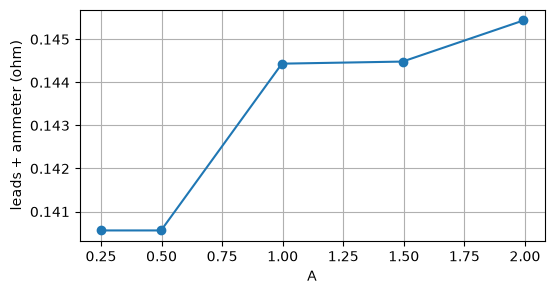

In [6]:
def step_points(folder):
    """One row per DPS step: median DMM amps and median DPS volts over the last 40 % of the hold."""
    dmm = b41t.load(folder / "dmm.csv")
    dmm = dmm[dmm.function == "DC A"].dropna(subset=["value"])
    dps = pd.read_csv(folder / "dps.csv")
    ev = pd.read_csv(folder / "events.csv")
    ends = list(ev.t_host.iloc[1:]) + [dps.t_host.iloc[-1]]
    rows = []
    for (_, e), t_end in zip(ev.iterrows(), ends):
        t_from = e.t_host + 0.6 * (t_end - e.t_host)
        i = dmm.value[(dmm.t_host >= t_from) & (dmm.t_host < t_end)].median()
        v = dps.volts[(dps.t_host >= t_from) & (dps.t_host < t_end)].median()
        rows.append({"amps": i, "volts": v})
    return pd.DataFrame(rows)

leads = step_points(CAPTURE / "leads")
leads["r_ohm"] = leads.volts / leads.amps

def r_leads(amps):
    """The leads' resistance at a current, interpolated between the leads run's steps."""
    return np.interp(amps, leads.amps, leads.r_ohm)

show(leads, n=None)
R_LEADS_1A = float(r_leads(1.0))
print(f"leads + ammeter: {leads.r_ohm.min():.4f} to {leads.r_ohm.max():.4f} ohm over {leads.amps.min():.2f} to {leads.amps.max():.2f} A")
leads.plot(x="amps", y="r_ohm", style="o-", figsize=(6, 3), grid=True, legend=False, ylabel="leads + ammeter (ohm)", xlabel="A");

The leads' resistance against the current through them. A rise with current is the leads and the ammeter's shunt warming. The lowest point is the least certain, since at 0.25 A the DPS readback is a few tens of millivolts read to one millivolt.

### Each load

The rest reading first, then the driven points and the line through them.

bare    cold 5.092 +/- 0.003 ohm, drift +1.87 mohm/W, rest two-wire 5.05 ohm, up to 11.8 W
cap     cold 5.090 +/- 0.002 ohm, drift +2.77 mohm/W, rest two-wire 5.04 ohm, up to 11.8 W
series  cold 15.269 +/- 0.011 ohm, drift +0.97 mohm/W, rest two-wire 15.12 ohm, up to 20.8 W


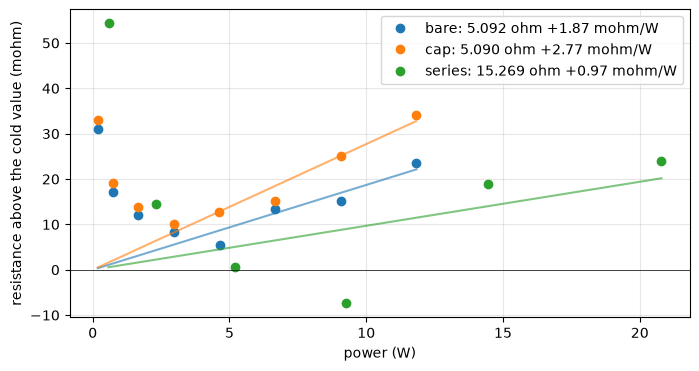

In [7]:
def rest_ohms(folder):
    log = b41t.load(folder / "rest.csv")
    log = log[log.function == "ohm"].dropna(subset=["value"])
    marks = pd.read_csv(folder / "marks.csv").set_index("mark").t_host
    short = log.value[(log.t_host >= marks["shorted"] + 3) & (log.t_host < marks["load"])].median()
    load = log.value[log.t_host >= marks["load"] + 5].median()
    return load - short, short

out = {}
fig, ax = plt.subplots(figsize=(8, 4))
for name in ("bare", "cap", "series"):
    folder = CAPTURE / name
    if not (folder / "dmm.csv").exists():
        print(name, "not captured"); continue
    pts = step_points(folder)
    pts["r_ohm"] = pts.volts / pts.amps - r_leads(pts.amps)
    pts["power_w"] = pts.r_ohm * pts.amps ** 2
    fit = pts[pts.power_w >= 2.0]
    k, r0 = np.polyfit(fit.power_w, fit.r_ohm, 1)
    resid = fit.r_ohm - (r0 + k * fit.power_w)
    se = resid.std(ddof=2) / np.sqrt(len(fit))
    rest, probe_zero = rest_ohms(folder)
    out[name] = {"pts": pts, "r0": r0, "k": k, "se": se, "rest": rest}
    print(f"{name:7s} cold {r0:.3f} +/- {2 * se:.3f} ohm, drift {1e3 * k:+.2f} mohm/W, rest two-wire {rest:.2f} ohm, up to {pts.power_w.max():.1f} W")
    ax.plot(pts.power_w, 1e3 * (pts.r_ohm - r0), "o", label=f"{name}: {r0:.3f} ohm {1e3 * k:+.2f} mohm/W")
    ax.plot(pts.power_w, 1e3 * k * pts.power_w, "-", color=ax.lines[-1].get_color(), alpha=0.6)
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel("power (W)"); ax.set_ylabel("resistance above the cold value (mohm)"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

Each load's resistance above its own cold value, in milliohms, against the power it dissipates, with the line fitted to the points at 2 W and above. The points below 2 W sit above the line by an amount that shrinks as the current grows, about 30 mohm at 0.19 A, 15 at 0.38 A and 10 at 0.57 A. That is the shape of a fixed offset. An error of about 1.5 mA in the current, or the same thing as a few millivolts in the voltage, divided by the current, gives it. A fit of each load with an offset term puts the offset at 1.3 to 1.9 mA, which sits inside the DMM's accuracy on its 20 A range, where the last few counts are milliamps. Those points carry the meter rather than the part and are left out of the fit. From 2 W up the single parts rise 2 to 3 mohm per watt, 25 to 35 mohm by the top step. That is the warm-up at 12 W, about half a percent. The series load spreads the same current over three cases. Its points scatter by a few tens of milliohms around the line, which is the same relative resolution on a three times larger value.

The slopes are expected to be alike in ohm per watt, series included. Three times the resistance with a third of the warming per part gives the same absolute slope. They come out at about 2, 3 and 1 mohm/W with fit errors of 0.3 to 0.9, so they agree within what the method resolves. They are not a property of the part alone. The slope is the resistance times the wire's temperature coefficient times the thermal resistance to the air, and the last factor depends on how each part sat on the bench. The 25 s holds are also much shorter than the part's thermal time constant, so each step's temperature is the heat built up over the run so far. Read as a material figure, 2 mohm/W on 5 ohm is 400 ppm per watt. With a bare case at roughly 10 to 20 K/W that is 20 to 40 ppm per kelvin, which is in the range of a resistance alloy.

The two-wire rest readings come out about 50 mohm under the driven cold values once the probe zero is taken out. The B41T+ reads ohms to 10 mohm with a stated accuracy of a few tens of milliohms at this range, and the driven path has two clip to lug contacts the leads run did not. The gap sits inside what either explanation allows, so this capture does not say which it is.

## Results

One entry per load. The cold value with its two standard error bounds, the drift in ohm per watt, the two-wire rest reading, and the highest power the fit covers. Stage 1 reads the cold value and the drift to correct a load for the power it ran at, and stays under the highest power listed.

In [8]:
fields = {}
for name, d in out.items():
    fields[name] = {
        "r_cold": results.quantity(d["r0"], d["r0"] - 2 * d["se"], d["r0"] + 2 * d["se"], "ohm"),
        "drift": results.quantity(d["k"], unit="ohm/W"),
        "rest_two_wire": results.quantity(d["rest"], unit="ohm"),
        "power_max": results.quantity(d["pts"].power_w.max(), unit="W"),
    }
results.write("0-instruments", "power-resistors", CAPTURE,
              notes="wirewound parts, a few uH each, from the part class; r_cold excludes the leads and the ammeter, subtracted at the matching current",
              leads=results.quantity(R_LEADS_1A, leads.r_ohm.min(), leads.r_ohm.max(), "ohm"), **fields)

PosixPath('/home/aaron/projects/OpenServoCore/notebooks/stages/0-instruments/power-resistors/results.json')

## Limitations

- The driven value inherits the DMM's DC A accuracy and the DPS's voltage readback. The readback agrees with the DMM within millivolts, but the DMM's own accuracy comes from its manual.
- The straight line holds over the power range used here, under 15 W per part. The parts are rated 50 W. Above the range measured the line is an extrapolation.
- The drift slope belongs to this schedule and placement, 25 s steps with the part loose on the bench, not to the part alone. A heatsink or a longer hold changes it.
- The lead resistance is measured in its own run and subtracted at the matching current, but the clip contacts are remade for every wiring and can differ by some milliohms from run to run.
- The loads include their soldered wires. Clipping at a different point on a wire moves the value by about a milliohm, below the error bar, but a load used without those wires is a different load.

## Open questions

- The inductance of the wirewound parts, which matters for stage 1's current ripple and is only quoted from the part class here. A measurement with a known step and the board's own current sense in stage 1 would give it.
- How hot the single parts get at the top step. They were uncomfortable to touch after a run at 12 W with no heatsink. A thermocouple on the case during a repeat would put a temperature on it and say how long a stage 1 run can hold that power.

## Conclusion

The three loads can be treated as fixed resistances over the power range used here, up to 12 W for a single part and 21 W for the series load. Each one stays within 0.5 percent of its cold value. The single parts warm by 2 to 3 mohm per watt, 25 to 35 mohm at the top. Stage 1 can take the cold value from the result file and skip the power correction inside that range, as long as 0.3 percent is inside what it is measuring.

The cold values are 5.09 ohm for both single parts and 15.27 ohm for the series load, known to a few milliohms. The capacitor across the second load makes no difference at DC. The two single parts agree to two milliohms. The series load reads three times the bare part to within 0.1 percent, so the three parts match.

For stage 1 this means three things.

- Use the driven cold values, not the two-wire ohms readings. The ohms reading sits about 50 mohm low on a 5 ohm part, which is a percent. The leads and the ammeter add about 0.14 ohm to anything measured through them, a little more as they warm.
- Stay under the powers listed in the result file. Above 12 W a single part with no heatsink gets hot quickly, and the straight line is not measured there.
- Do not use the DMM's 20 A range for currents under about half an amp when a percent matters. Its fixed error of a couple of milliamps showed as a 1/I bulge in the lowest steps here. A lower current range, or the board's own current sense once stage 1 has graded it, would do better there.